### **Ứng dụng Singular Value Decomposition (SVD) và Principal Component Analysis (PCA) trong phát hiện tin nhắn rác**

Notebook này nghiên cứu hai phép phân tích ma trận có quan hệ chặt chẽ với nhau, Singular Value Decomposition (SVD) và Principal Component Analysis (PCA), rồi áp dụng chúng cho một bài toán phân loại văn bản: xác định một tin nhắn SMS có phải là tin rác hay không. Cả hai phương pháp được cài đặt từ đầu bằng NumPy, đối chiếu với `scikit-learn`, và dùng làm bước giảm chiều đặt trước một bộ phân loại tuyến tính. Nửa sau của notebook kiểm chứng các kết quả lý thuyết chính (định lý Eckart–Young, sự tương đương giữa PCA và SVD của dữ liệu đã tâm hóa, vai trò của tâm hóa) ngay trên ma trận TF-IDF thực tế.

Phần cơ sở toán học với chứng minh đầy đủ nằm trong `slide/script.md`. Các tham chiếu PHẦN 1, PHẦN 2, ... dưới đây trỏ đến file đó.

### **Bộ dữ liệu sử dụng**

Dữ liệu là SMS Spam Collection từ UCI Machine Learning Repository: 5.574 tin nhắn SMS tiếng Anh, mỗi tin được gán nhãn `ham` (tin thường) hoặc `spam` (tin rác). Đây là một bộ dữ liệu nhỏ, mất cân bằng mạnh (khoảng 13% spam), văn bản ngắn và nhiều nhiễu, nên rất phù hợp để thử nghiệm biểu diễn bag-of-words và các phương pháp giảm chiều bằng đại số tuyến tính.

Mục tiêu:

1. Xây dựng biểu diễn TF-IDF cho tin nhắn và tìm hiểu hình học của nó (độ thưa, phổ giá trị kỳ dị).
2. Cài đặt SVD và PCA từ đầu, bao gồm một phiên bản randomized SVD không bao giờ tạo ra ma trận đặc, và xác nhận kết quả trùng với `scikit-learn`.
3. So sánh bộ phân loại logistic regression huấn luyện trên (a) ma trận TF-IDF đầy đủ, (b) đặc trưng LSA (truncated SVD) và (c) đặc trưng PCA với nhiều giá trị số chiều $k$.
4. Kiểm chứng lý thuyết bằng thực nghiệm: tính tối ưu của truncated SVD (Eckart–Young), PCA là SVD của dữ liệu đã tâm hóa, và vì sao phải tâm hóa.

In [1]:
import os
import re
import io
import html
import time
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = os.path.join(os.getcwd(), "data")
DATA_PATH = os.path.join(DATA_DIR, "SMSSpamCollection")

# One palette for the whole notebook, so a colour always means the same thing.
COLORS = {
    "ham": "#2a78d6", "spam": "#eb6834",
    "lsa": "#2a78d6", "pca": "#eb6834", "baseline": "#1baf7a",
    "theory": "#0b0b0b", "random": "#eda100", "columns": "#6250d6",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "muted": "#898781",
}
plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (8, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": COLORS["axis"], "axes.labelcolor": "#52514e",
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
DIVERGING_CMAP = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#2a78d6", "#0d366b"])
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 90)

### **Tải và đọc dữ liệu**

File nén được tải từ UCI; nếu thất bại thì dùng bản sao trên GitHub của cùng file đó. Nếu file đã có sẵn trong `data/` thì đọc trực tiếp. File ở dạng phân tách bằng tab, không có dòng tiêu đề. Bắt buộc dùng `quoting=3` (`csv.QUOTE_NONE`) vì nhiều tin nhắn chứa dấu nháy không khép, nếu không chúng sẽ "nuốt" nhiều dòng liền nhau.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
MIRROR_URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"


def download_dataset(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    try:
        with urllib.request.urlopen(UCI_URL, timeout=60) as resp:
            archive = zipfile.ZipFile(io.BytesIO(resp.read()))
        with archive.open("SMSSpamCollection") as src, open(path, "wb") as dst:
            dst.write(src.read())
        print("Downloaded from UCI.")
    except Exception as exc:
        print(f"UCI download failed ({exc}); using mirror.")
        with urllib.request.urlopen(MIRROR_URL, timeout=60) as resp, open(path, "wb") as dst:
            dst.write(resp.read())


if not os.path.exists(DATA_PATH):
    download_dataset(DATA_PATH)
else:
    print("Using existing file:", DATA_PATH)

raw = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "text"],
                  quoting=3, encoding="utf-8")
raw["is_spam"] = (raw["label"] == "spam").astype(int)
print(raw.shape)
raw.head()

Using existing file: D:\Spam Detection\data\SMSSpamCollection
(5574, 3)


,label,text,is_spam
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


### **Mô tả dữ liệu**

Phân bố nhãn, độ dài tin nhắn theo lớp, vài ví dụ thô và các từ xuất hiện nhiều nhất trong mỗi lớp. Histogram dùng mật độ thay vì số đếm vì hai lớp có kích thước rất khác nhau.

In [3]:
counts = raw["label"].value_counts()
print(counts.to_string())
print(f"spam share: {counts['spam'] / len(raw):.3%}")
print("duplicated rows:", raw.duplicated().sum())

raw["n_chars"] = raw["text"].str.len()
raw["n_words"] = raw["text"].str.split().str.len()
print()
print(raw.groupby("label")[["n_chars", "n_words"]].describe().round(1).T.to_string())

label
ham     4827
spam     747
spam share: 13.402%
duplicated rows: 403

label             ham   spam
n_chars count  4827.0  747.0
        mean     71.5  138.7
        std      58.3   28.9
        min       2.0   13.0
        25%      33.0  133.0
        50%      52.0  149.0
        75%      93.0  157.0
        max     910.0  223.0
n_words count  4827.0  747.0
        mean     14.3   23.9
        std      11.5    5.8
        min       1.0    2.0
        25%       7.0   22.0
        50%      11.0   25.0
        75%      19.0   28.0
        max     171.0   35.0


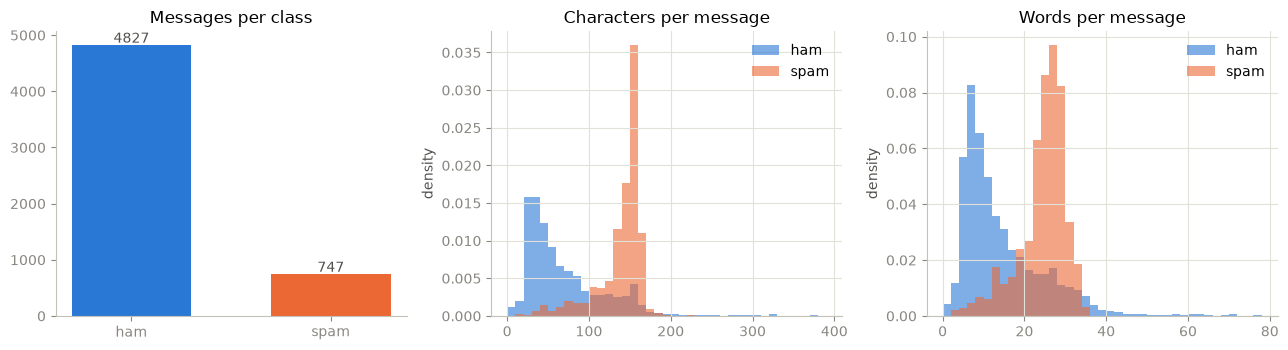

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

axes[0].bar(counts.index, counts.values, color=[COLORS["ham"], COLORS["spam"]], width=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 40, str(v), ha="center", color="#52514e")
axes[0].set_title("Messages per class")
axes[0].grid(False)

for ax, col, title, bins in [(axes[1], "n_chars", "Characters per message", np.arange(0, 400, 10)),
                             (axes[2], "n_words", "Words per message", np.arange(0, 80, 2))]:
    for label in ["ham", "spam"]:
        ax.hist(raw.loc[raw["label"] == label, col], bins=bins, density=True,
                alpha=0.6, color=COLORS[label], label=label)
    ax.set_title(title)
    ax.set_ylabel("density")
    ax.legend()
plt.tight_layout()
plt.show()

In [5]:
pd.set_option("display.max_colwidth", 160)
print("ham examples")
for t in raw.loc[raw["label"] == "ham", "text"].sample(4, random_state=RANDOM_STATE):
    print("  ", t)
print("\nspam examples")
for t in raw.loc[raw["label"] == "spam", "text"].sample(4, random_state=RANDOM_STATE):
    print("  ", t)

ham examples
   Dear,Me at cherthala.in case u r coming cochin pls call bfore u start.i shall also reach accordingly.or tell me which day u r coming.tmorow i am engaged ans its holiday.
   Ok. I only ask abt e movie. U wan ktv oso?
   Convey my regards to him
   Hi Jon, Pete here, Ive bin 2 Spain recently & hav sum dinero left, Bill said u or ur rents mayb interested in it, I hav 12,000pes, so around £48, tb, James.

spam examples
   Summers finally here! Fancy a chat or flirt with sexy singles in yr area? To get MATCHED up just reply SUMMER now. Free 2 Join. OptOut txt STOP Help08714742804
   This is the 2nd time we have tried 2 contact u. U have won the 750 Pound prize. 2 claim is easy, call 08718726970 NOW! Only 10p per min. BT-national-rate 
   Get ur 1st RINGTONE FREE NOW! Reply to this msg with TONE. Gr8 TOP 20 tones to your phone every week just £1.50 per wk 2 opt out send STOP 08452810071 16
   Ur cash-balance is currently 500 pounds - to maximize ur cash-in now send GO to 866

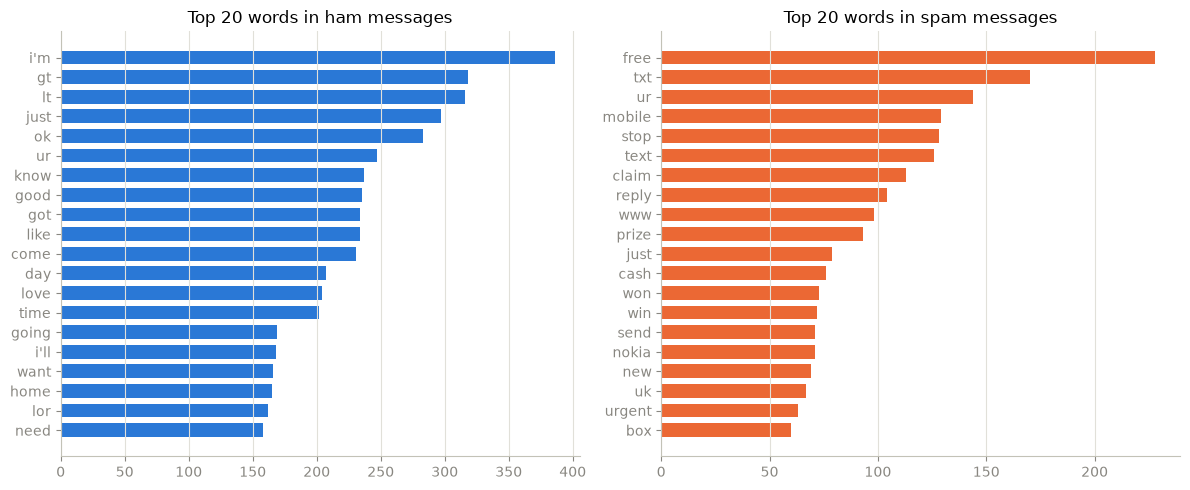

In [6]:
def top_words(texts, n=20):
    counter = Counter()
    for text in texts:
        counter.update(w for w in re.findall(r"[a-z']+", text.lower())
                       if w not in ENGLISH_STOP_WORDS and len(w) > 1)
    return counter.most_common(n)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label in zip(axes, ["ham", "spam"]):
    words, freqs = zip(*top_words(raw.loc[raw["label"] == label, "text"]))
    ax.barh(words[::-1], freqs[::-1], color=COLORS[label], height=0.7)
    ax.set_title(f"Top 20 words in {label} messages")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Hai lớp khác nhau về độ dài (tin spam thường dài, sát giới hạn 160 ký tự) và về từ vựng: spam bị chi phối bởi các từ như *free*, *call*, *txt*, *claim*, *prize*, còn ham mang tính hội thoại. Một mô hình tuyến tính trên đặc trưng từ vì vậy sẽ hoạt động tốt; câu hỏi được nghiên cứu ở đây là bao nhiêu phần của tín hiệu đó còn giữ được sau khi chiếu xuống một không gian con số chiều thấp.

### **Tiền xử lý**

**Chuẩn hóa văn bản.** Tin nhắn thô chứa thực thể HTML (`&lt;#&gt;`, `&amp;`), URL, số điện thoại, giá tiền và rất nhiều chữ số. Từng số điện thoại hay số tiền cụ thể không bao giờ lặp lại nên vô dụng với tư cách đặc trưng; điều quan trọng là tin nhắn *có* chứa số điện thoại hay giá tiền. Vì vậy `normalize_text` thay mỗi mẫu như thế bằng một token đại diện trước khi chuyển về chữ thường và bỏ dấu câu. Các phép thay được áp dụng theo thứ tự cố định (URL, email, tiền, chuỗi chữ số dài, số còn lại) để mỗi ký tự được nhận bởi mẫu cụ thể nhất trước.

In [7]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+|\b\S+\.(?:com|co\.uk|net|org)\b)")
EMAIL_RE = re.compile(r"\S+@\S+")
MONEY_RE = re.compile(r"[£$€]\s*\d+(?:[.,]\d+)?|\b\d+(?:[.,]\d+)?\s*(?:p|pence|pounds?)\b")
PHONE_RE = re.compile(r"\d{5,}")          # phone numbers and 5-digit short codes
NUMBER_RE = re.compile(r"\d+")
NON_ALPHA_RE = re.compile(r"[^a-z\s]")


def normalize_text(text):
    text = html.unescape(text).lower()
    text = URL_RE.sub(" urltoken ", text)
    text = EMAIL_RE.sub(" emailtoken ", text)
    text = MONEY_RE.sub(" moneytoken ", text)
    text = PHONE_RE.sub(" phonetoken ", text)
    text = NUMBER_RE.sub(" numtoken ", text)
    text = NON_ALPHA_RE.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


for text in raw["text"].iloc[[2, 8, 11, 44]]:
    print(text)
    print("  ->", normalize_text(text))
    print()

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  -> free entry in numtoken a wkly comp to win fa cup final tkts numtoken st may numtoken text fa to phonetoken to receive entry question std txt rate t c s apply phonetoken over numtoken s

WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
  -> winner as a valued network customer you have been selected to receivea moneytoken prize reward to claim call phonetoken claim code kl numtoken valid numtoken hours only

SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info
  -> six chances to win cash from numtoken to moneytoken txt csh numtoken and send to phonetoken cost moneytoken day numtoken days numtoken tsandcs apply reply hl numtoken info

Great

**Loại trùng lặp và chia tập.** Có 403 tin nhắn xuất hiện nhiều hơn một lần. Nếu giữ lại, các bản sao của cùng một tin có thể rơi vào cả tập huấn luyện lẫn tập kiểm tra, làm điểm kiểm tra bị lạc quan. Chúng được loại bỏ trước mọi phép chia. Sau đó dữ liệu được chia 80/20 thành tập huấn luyện và tập kiểm tra có phân tầng theo nhãn, và phần huấn luyện được chia tiếp 75/25 thành tập huấn luyện con và tập kiểm định. Tập kiểm định dùng để chọn số thành phần $k$; tập kiểm tra chỉ được chạm đến đúng một lần, ở bước đánh giá cuối.

In [8]:
data = raw.drop_duplicates(subset=["label", "text"]).reset_index(drop=True)
data["clean"] = data["text"].map(normalize_text)
print("after removing duplicates:", data.shape[0], "messages")
print(data["label"].value_counts().to_string())

train_df, test_df = train_test_split(data, test_size=0.20, stratify=data["is_spam"],
                                     random_state=RANDOM_STATE)
sub_df, val_df = train_test_split(train_df, test_size=0.25, stratify=train_df["is_spam"],
                                  random_state=RANDOM_STATE)
for name, part in [("train", train_df), ("  sub-train", sub_df), ("  validation", val_df), ("test", test_df)]:
    print(f"{name:14s} {len(part):5d} messages, spam share {part['is_spam'].mean():.3f}")

y_train, y_test = train_df["is_spam"].to_numpy(), test_df["is_spam"].to_numpy()
y_sub, y_val = sub_df["is_spam"].to_numpy(), val_df["is_spam"].to_numpy()

after removing duplicates: 5171 messages
label
ham     4518
spam     653
train           4136 messages, spam share 0.126
  sub-train     3102 messages, spam share 0.126
  validation    1034 messages, spam share 0.126
test            1035 messages, spam share 0.127


**TF-IDF.** Mỗi tin nhắn trở thành một hàng của ma trận $X \in \mathbb{R}^{n \times d}$ với các cột là unigram và bigram. Trọng số của từ $t$ trong tài liệu $i$ là

$$
x_{it} = \big(1 + \log \mathrm{tf}_{it}\big)\cdot \log\frac{1 + n}{1 + \mathrm{df}_t} + 1 ,
$$

sau đó mỗi hàng được chuẩn hóa $\ell_2$ (`sublinear_tf=True`, idf làm trơn mặc định, xem PHẦN 4). Các từ xuất hiện trong ít hơn hai tài liệu huấn luyện bị loại, và stop word tiếng Anh được bỏ. Bộ vector hóa chỉ được fit trên tin nhắn huấn luyện; tập kiểm tra chỉ được transform. Với bước quét chọn mô hình, một bộ vector hóa thứ hai được fit trên tập huấn luyện con, để tập kiểm định không bao giờ ảnh hưởng đến từ điển hay trọng số idf.

In [9]:
def make_vectorizer():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")


vectorizer = make_vectorizer().fit(train_df["clean"])
X_train = vectorizer.transform(train_df["clean"]).tocsr()
X_test = vectorizer.transform(test_df["clean"]).tocsr()

vectorizer_sub = make_vectorizer().fit(sub_df["clean"])
X_sub = vectorizer_sub.transform(sub_df["clean"]).tocsr()
X_val = vectorizer_sub.transform(val_df["clean"]).tocsr()

vocab = np.array(vectorizer.get_feature_names_out())
n_docs, n_terms = X_train.shape
density = X_train.nnz / (n_docs * n_terms)
dense_bytes = n_docs * n_terms * 8
sparse_bytes = X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes
print(f"X_train: {X_train.shape}, non-zeros: {X_train.nnz}, density: {density:.4%}")
print(f"X_test : {X_test.shape}")
print(f"X_sub  : {X_sub.shape}, X_val: {X_val.shape} (vocabulary fitted on sub-train)")
print(f"average non-zero terms per message: {X_train.nnz / n_docs:.1f}")
print(f"dense storage: {dense_bytes / 2**20:.1f} MiB, CSR storage: {sparse_bytes / 2**20:.2f} MiB "
      f"(ratio {dense_bytes / sparse_bytes:.0f}x)")
print("sample vocabulary:", ", ".join(vocab[np.random.default_rng(RANDOM_STATE).choice(n_terms, 12, replace=False)]))

X_train: (4136, 5649), non-zeros: 37349, density: 0.1599%
X_test : (1035, 5649)
X_sub  : (3102, 4216), X_val: (1034, 4216) (vocabulary fitted on sub-train)
average non-zero terms per message: 9.0
dense storage: 178.3 MiB, CSR storage: 0.44 MiB (ratio 402x)
sample vocabulary: logos, campus, sitting, nap, plan, thoughts, care, ll major, catching, ready time, work today, dough


### **Cài đặt SVD và PCA từ đầu**

**SVD qua trị riêng của $A^\mathsf{T}A$.** Chứng minh xây dựng của SVD (PHẦN 1) đồng thời là một thuật toán. Với $A \in \mathbb{R}^{m \times n}$, ma trận $A^\mathsf{T}A$ đối xứng nửa xác định dương nên có cơ sở trực chuẩn gồm các vectơ riêng $v_1, \dots, v_n$ với trị riêng $\lambda_1 \ge \dots \ge \lambda_n \ge 0$. Đặt $\sigma_i = \sqrt{\lambda_i}$ và $u_i = A v_i / \sigma_i$ với $\sigma_i > 0$ ta được các vectơ kỳ dị trái trực chuẩn, và $A = U \Sigma V^\mathsf{T}$. Khi $n > m$, chéo hóa $AA^\mathsf{T}$ rẻ hơn; điều này được xử lý bằng cách áp dụng cùng thủ tục cho $A^\mathsf{T}$.

Một chi tiết về số học: trị riêng của $A^\mathsf{T}A$ được tính với sai số tuyệt đối cỡ $\lambda_1 \varepsilon$, nên một giá trị kỳ dị chỉ đáng tin nếu $\sigma_i^2 > \lambda_1 \cdot \max(m,n)\,\varepsilon$. Các giá trị kỳ dị dưới ngưỡng đó được coi là 0, và đó là cách xác định hạng số học. Bình phương ma trận cũng bình phương số điều kiện của nó, vì thế phương pháp này là công cụ để học chứ không phải cách LAPACK làm.

In [10]:
def svd_via_eig(A):
    """Compact SVD of a dense matrix via the eigendecomposition of A^T A (or A A^T).

    Returns U (m x r), s (r,), Vt (r x n) with r the numerical rank.
    """
    A = np.asarray(A, dtype=float)
    m, n = A.shape
    if n > m:                                   # diagonalise the smaller Gram matrix
        U, s, Vt = svd_via_eig(A.T)
        return Vt.T, s, U.T
    lam, V = np.linalg.eigh(A.T @ A)            # ascending eigenvalues
    order = np.argsort(lam)[::-1]
    lam, V = lam[order], V[:, order]
    tol = lam[0] * max(m, n) * np.finfo(float).eps
    r = int(np.sum(lam > tol))
    s = np.sqrt(lam[:r])
    U = (A @ V[:, :r]) / s                      # u_i = A v_i / sigma_i
    return U, s, V[:, :r].T


def check_svd(A, U, s, Vt):
    """Compare a factorisation with numpy.linalg.svd and check orthonormality."""
    s_ref = np.linalg.svd(A, compute_uv=False)
    r = len(s)
    return {
        "shape": A.shape,
        "rank": r,
        "max |sigma - sigma_np| / sigma_1": np.max(np.abs(s - s_ref[:r])) / s_ref[0],
        "||A - U S Vt||_F / ||A||_F": np.linalg.norm(A - (U * s) @ Vt) / np.linalg.norm(A),
        "||U^T U - I||_F": np.linalg.norm(U.T @ U - np.eye(r)),
        "||V^T V - I||_F": np.linalg.norm(Vt @ Vt.T - np.eye(r)),
    }


rng = np.random.default_rng(RANDOM_STATE)
test_matrices = {
    "gaussian 200 x 60": rng.standard_normal((200, 60)),
    "gaussian 60 x 200": rng.standard_normal((60, 200)),
    "low-rank 150 x 80 (rank 5)": rng.standard_normal((150, 5)) @ rng.standard_normal((5, 80)),
    "TF-IDF block 300 x d": X_train[:300].toarray(),
}
rows = {}
for name, A in test_matrices.items():
    rows[name] = check_svd(A, *svd_via_eig(A))
svd_checks = pd.DataFrame(rows).T
for col in svd_checks.columns[2:]:
    svd_checks[col] = svd_checks[col].map("{:.2e}".format)
svd_checks

,shape,rank,max |sigma - sigma_np| / sigma_1,||A - U S Vt||_F / ||A||_F,||U^T U - I||_F,||V^T V - I||_F
gaussian 200 x 60,"(200, 60)",60,9.78e-16,1.65e-15,1.73e-14,1.25e-14
gaussian 60 x 200,"(60, 200)",60,9.83e-16,1.66e-15,1.26e-14,1.77e-14
low-rank 150 x 80 (rank 5),"(150, 80)",5,4.18e-16,6.40e-16,1.74e-15,1.09e-15
TF-IDF block 300 x d,"(300, 5649)",296,2.46e-15,2.17e-15,3.72e-14,4.31e-14


Cả bốn phân tích đều tái tạo giá trị kỳ dị của `numpy.linalg.svd` đến độ chính xác máy, tái tạo đúng ma trận và có các nhân tử trực chuẩn. Với ma trận hạng 5 và khối TF-IDF (có vài hàng phụ thuộc tuyến tính), ngưỡng hạng loại bỏ đúng các trị riêng gần 0 giả tạo.

**Randomized SVD.** Ma trận TF-IDF có kích thước $4136 \times 5649$ và hơn 99,8% phần tử bằng 0. Lập $A^\mathsf{T}A$ dạng đặc (ma trận $5649 \times 5649$) là lãng phí khi chỉ cần $k \ll \min(m, n)$ bộ ba kỳ dị. Thuật toán randomized SVD của Halko, Martinsson và Tropp (2011) chỉ chạm đến $A$ qua các tích $A M$ và $A^\mathsf{T} M$ với $M$ là ma trận đặc mỏng, rất rẻ khi $A$ thưa (PHẦN 4):

1. Lấy ma trận thử Gaussian $\Omega \in \mathbb{R}^{n \times \ell}$ với $\ell = k + p$ ($p$ = oversampling), tính $Y = A\Omega$ và trực chuẩn hóa, $Q = \mathrm{qr}(Y)$.
2. Power iteration: lặp $q$ lần $Q \leftarrow \mathrm{qr}(A\,\mathrm{qr}(A^\mathsf{T}Q))$. Mỗi vòng nhân các giá trị kỳ dị với $\sigma_i^2$, nên không gian cột của $Q$ hội tụ về span của các vectơ kỳ dị đầu; các bước QR trung gian tránh mất độ chính xác.
3. Chiếu: $B = Q^\mathsf{T}A \in \mathbb{R}^{\ell \times n}$, tính SVD nhỏ $B = \tilde U \Sigma V^\mathsf{T}$ và đặt $U = Q\tilde U$.

Cài đặt chấp nhận bất kỳ đối tượng nào có `shape`, `matmat` (cho $AM$) và `rmatmat` (cho $A^\mathsf{T}M$). Chính điều này cho phép chạy PCA trên ma trận thưa mà không bao giờ tâm hóa tường minh: toán tử $A - \mathbf{1}\mu^\mathsf{T}$ thỏa

$$
(A - \mathbf{1}\mu^\mathsf{T}) M = AM - \mathbf{1}(\mu^\mathsf{T} M), \qquad
(A - \mathbf{1}\mu^\mathsf{T})^\mathsf{T} M = A^\mathsf{T} M - \mu(\mathbf{1}^\mathsf{T} M),
$$

nên tâm hóa chỉ tốn một hiệu chỉnh hạng một cho mỗi phép nhân và ma trận đã tâm hóa dạng đặc không bao giờ được tạo ra. Các toán tử này cũng cung cấp ma trận Gram nhỏ $AA^\mathsf{T}$ (và $A^\mathsf{T}A$), cho một thuật toán chính xác dự phòng khi $n$ vừa phải: với toán tử đã tâm hóa, $X_cX_c^\mathsf{T} = XX^\mathsf{T} - (X\mu)\mathbf{1}^\mathsf{T} - \mathbf{1}(X\mu)^\mathsf{T} + \lVert\mu\rVert^2\mathbf{1}\mathbf{1}^\mathsf{T}$ và $X_c^\mathsf{T}X_c = X^\mathsf{T}X - n\,\mu\mu^\mathsf{T}$.

In [11]:
class SparseOperator:
    """Thin wrapper giving a sparse or dense matrix the matmat / rmatmat / gram interface."""

    def __init__(self, X):
        self.X = X
        self.shape = X.shape

    def matmat(self, M):
        return np.asarray(self.X @ M)

    def rmatmat(self, M):
        return np.asarray(self.X.T @ M)

    def gram(self):                   # X X^T  (m x m)
        return np.asarray((self.X @ self.X.T).todense() if sp.issparse(self.X) else self.X @ self.X.T)

    def gram_t(self):                 # X^T X  (n x n)
        return np.asarray((self.X.T @ self.X).todense() if sp.issparse(self.X) else self.X.T @ self.X)


class CenteredOperator:
    """The operator X - 1 mu^T, applied without materialising the centred matrix."""

    def __init__(self, X, mean):
        self.X = X
        self.mean = np.asarray(mean, dtype=float).ravel()
        self.shape = X.shape

    def matmat(self, M):
        return np.asarray(self.X @ M) - np.outer(np.ones(self.shape[0]), self.mean @ M)

    def rmatmat(self, M):
        return np.asarray(self.X.T @ M) - np.outer(self.mean, np.asarray(M).sum(axis=0))

    def gram(self):
        base = SparseOperator(self.X)
        x_mu = base.matmat(self.mean)                       # X mu
        G = base.gram()
        return G - x_mu[:, None] - x_mu[None, :] + self.mean @ self.mean

    def gram_t(self):
        return SparseOperator(self.X).gram_t() - self.shape[0] * np.outer(self.mean, self.mean)


def as_operator(A):
    if hasattr(A, "matmat") and hasattr(A, "rmatmat"):
        return A
    return SparseOperator(A)


def randomized_svd(A, k, n_oversamples=None, n_iter=10, random_state=None):
    """Rank-k approximate SVD (Halko, Martinsson, Tropp 2011) using only products with A and A^T."""
    A = as_operator(A)
    m, n = A.shape
    p = k if n_oversamples is None else n_oversamples
    ell = min(k + p, m, n)
    rng = np.random.default_rng(random_state)
    Omega = rng.standard_normal((n, ell))
    Q, _ = np.linalg.qr(A.matmat(Omega))
    for _ in range(n_iter):                       # power iterations with re-orthonormalisation
        Z, _ = np.linalg.qr(A.rmatmat(Q))
        Q, _ = np.linalg.qr(A.matmat(Z))
    B = A.rmatmat(Q).T                            # B = Q^T A, shape (ell, n)
    U_small, s, Vt = np.linalg.svd(B, full_matrices=False)
    U = Q @ U_small
    return U[:, :k], s[:k], Vt[:k]


def gram_svd(A, k):
    """Exact top-k SVD through the eigendecomposition of the smaller Gram matrix."""
    A = as_operator(A)
    m, n = A.shape
    if m <= n:
        lam, U = np.linalg.eigh(A.gram())
        order = np.argsort(lam)[::-1][:k]
        s = np.sqrt(np.clip(lam[order], 0.0, None))
        U = U[:, order]
        Vt = (A.rmatmat(U) / s).T                # v_i = A^T u_i / sigma_i
        return U, s, Vt
    lam, V = np.linalg.eigh(A.gram_t())
    order = np.argsort(lam)[::-1][:k]
    s = np.sqrt(np.clip(lam[order], 0.0, None))
    V = V[:, order]
    U = A.matmat(V) / s
    return U, s, V.T

**Cần bao nhiêu vòng power iteration?** Độ chính xác của phương pháp randomized SVD phụ thuộc vào tốc độ suy giảm của các giá trị kỳ dị sau chỉ số $k$. Ma trận văn bản có phổ rất phẳng (xem mục tiếp theo), nên các thiết lập mặc định dùng cho ảnh hay dữ liệu gợi ý là không đủ. Bảng dưới so sánh 50 giá trị kỳ dị đầu thu được với các mức oversampling $p$ và số vòng lặp $q$ khác nhau so với giá trị chính xác từ ARPACK.

In [12]:
K_CHECK = 50
svd_ref = TruncatedSVD(K_CHECK, algorithm="arpack", random_state=RANDOM_STATE).fit(X_train)
sigma_ref = svd_ref.singular_values_

records = []
for p in [10, K_CHECK, 2 * K_CHECK]:
    for q in [4, 7, 10]:
        t0 = time.perf_counter()
        _, s, _ = randomized_svd(X_train, K_CHECK, n_oversamples=p, n_iter=q, random_state=RANDOM_STATE)
        elapsed = time.perf_counter() - t0
        rel = np.abs(s - sigma_ref) / sigma_ref
        records.append({"oversampling p": p, "power iterations q": q,
                        "max rel. error": rel.max(), "mean rel. error": rel.mean(), "time (s)": elapsed})
convergence = pd.DataFrame(records)
for col in ["max rel. error", "mean rel. error"]:
    convergence[col] = convergence[col].map("{:.2e}".format)
convergence.round({"time (s)": 2})

,oversampling p,power iterations q,max rel. error,mean rel. error,time (s)
0,10,4,4.69e-02,1.13e-02,0.20
1,10,7,2.17e-02,3.19e-03,0.30
2,10,10,1.25e-02,1.38e-03,0.42
3,50,4,9.41e-03,2.48e-03,0.42
4,50,7,1.83e-03,2.31e-04,0.65
5,50,10,2.55e-04,2.44e-05,0.89
6,100,4,1.91e-03,4.24e-04,0.75
7,100,7,6.96e-05,9.52e-06,1.39
8,100,10,2.39e-06,2.52e-07,1.83


Với $p = 10$ và $q = 4$ (một mặc định phổ biến), các giá trị kỳ dị ở đuôi khối lệch khoảng 1%; với $p = k$ và $q = 10$ sai số giảm xuống dưới $10^{-3}$ với chi phí vừa phải. Đó là các giá trị mặc định dùng trong các lớp bên dưới. Sai số luôn lớn nhất ở các chỉ số cuối $i \approx k$, đúng như lý thuyết dự đoán: đó là những hướng khó tách nhất khỏi các hướng ngay dưới ngưỡng cắt.

**Các lớp giảm chiều.** `TruncatedSVDScratch` (Latent Semantic Analysis, không tâm hóa) và `PCAScratch` (tâm hóa qua toán tử ngầm) dùng chung một cài đặt. Cả hai cung cấp thuật toán randomized SVD và thuật toán chính xác qua ma trận Gram. Với PCA, phương sai giải thích của thành phần $i$ là $\sigma_i^2 / (n - 1)$ (PHẦN 2), và tổng phương sai $\operatorname{tr}(C) = \big(\lVert X\rVert_F^2 - n\lVert\mu\rVert^2\big)/(n-1)$ được tính mà không cần tâm hóa. Với LSA, theo quy ước của `scikit-learn`: phương sai giải thích là phương sai mẫu của các điểm chiếu, chia cho tổng phương sai của $X$.

In [13]:
class _SpectralReducer:
    """Rank-k projection X -> X V_k (optionally after centering)."""

    center = False

    def __init__(self, n_components, algorithm="randomized", n_oversamples=None,
                 n_iter=10, random_state=None):
        self.n_components = n_components
        self.algorithm = algorithm
        self.n_oversamples = n_oversamples
        self.n_iter = n_iter
        self.random_state = random_state

    def _operator(self, X):
        return CenteredOperator(X, self.mean_) if self.center else SparseOperator(X)

    def fit(self, X):
        n = X.shape[0]
        self.mean_ = np.asarray(X.mean(axis=0)).ravel()
        op = self._operator(X)
        if self.algorithm == "exact":
            U, s, Vt = gram_svd(op, self.n_components)
        else:
            U, s, Vt = randomized_svd(op, self.n_components, self.n_oversamples,
                                      self.n_iter, self.random_state)
        self.components_ = Vt
        self.singular_values_ = s
        sq_norm = X.multiply(X).sum() if sp.issparse(X) else np.sum(X ** 2)
        self.total_variance_ = (sq_norm - n * self.mean_ @ self.mean_) / (n - 1)
        if self.center:
            self.explained_variance_ = s ** 2 / (n - 1)
        else:
            self.explained_variance_ = self.transform(X).var(axis=0, ddof=1)
        self.explained_variance_ratio_ = self.explained_variance_ / self.total_variance_
        return self

    def transform(self, X):
        Z = np.asarray(X @ self.components_.T)
        if self.center:
            Z -= self.mean_ @ self.components_.T
        return Z

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        X_hat = Z @ self.components_
        return X_hat + self.mean_ if self.center else X_hat


class TruncatedSVDScratch(_SpectralReducer):
    """Latent semantic analysis: truncated SVD of the raw TF-IDF matrix."""
    center = False


class PCAScratch(_SpectralReducer):
    """PCA: truncated SVD of the centred matrix, computed without densifying it."""
    center = True

**Đối chiếu với scikit-learn tại $k = 50$.** `TruncatedSVD(algorithm="arpack")` và `PCA(svd_solver="arpack")` (nhận đầu vào thưa từ scikit-learn 1.4) được dùng làm tham chiếu. Vectơ kỳ dị chỉ xác định sai khác dấu, nên phép so sánh dùng $|\cos|$ giữa các thành phần tương ứng.

In [14]:
pca_ref = PCA(K_CHECK, svd_solver="arpack", random_state=RANDOM_STATE).fit(X_train)


def compare_with_sklearn(ours, ref):
    sigma_ours, sigma_ref = ours.singular_values_, ref.singular_values_
    cos = np.abs(np.sum(ours.components_ * ref.components_, axis=1))
    return {
        "max rel. sigma error": np.max(np.abs(sigma_ours - sigma_ref) / sigma_ref),
        "min |cos| components": cos.min(),
        "mean |cos| components": cos.mean(),
        "sum EVR (ours)": ours.explained_variance_ratio_.sum(),
        "sum EVR (sklearn)": ref.explained_variance_ratio_.sum(),
    }


comparison = {}
for name, cls, ref in [("LSA", TruncatedSVDScratch, svd_ref), ("PCA", PCAScratch, pca_ref)]:
    for algorithm in ["randomized", "exact"]:
        t0 = time.perf_counter()
        model = cls(K_CHECK, algorithm=algorithm, random_state=RANDOM_STATE).fit(X_train)
        row = compare_with_sklearn(model, ref)
        row["fit time (s)"] = time.perf_counter() - t0
        comparison[f"{name} ({algorithm})"] = row
comparison = pd.DataFrame(comparison).T
comparison["max rel. sigma error"] = comparison["max rel. sigma error"].map("{:.2e}".format)
comparison.round({"min |cos| components": 6, "mean |cos| components": 6, "sum EVR (ours)": 5,
                  "sum EVR (sklearn)": 5, "fit time (s)": 2})

,max rel. sigma error,min |cos| components,mean |cos| components,sum EVR (ours),sum EVR (sklearn),fit time (s)
LSA (randomized),2.55e-04,0.998348,0.999888,0.14742,0.14742,0.90
LSA (exact),2.38e-15,1.000000,1.000000,0.14742,0.14742,6.07
PCA (randomized),2.02e-04,0.998797,0.999910,0.14826,0.14826,0.91
PCA (exact),2.48e-15,1.000000,1.000000,0.14826,0.14826,5.01


Thuật toán Gram chính xác trùng với ARPACK đến cỡ $10^{-10}$; thuật toán randomized SVD với mặc định đã chọn sai lệch dưới $10^{-3}$ trên mọi giá trị kỳ dị, và các không gian con trùng nhau ($|\cos| \approx 1$ với mọi thành phần). Tỉ lệ phương sai giải thích trùng khớp, xác nhận công thức tổng phương sai và quy ước $\sigma_i^2/(n-1)$ được cài đặt giống `scikit-learn`.

### **Phổ giá trị kỳ dị**

Vì $n = 4136 < d = 5649$, ma trận $X$ có nhiều nhất $n$ giá trị kỳ dị khác 0 và chúng là căn bậc hai các trị riêng của ma trận Gram $G = XX^\mathsf{T} \in \mathbb{R}^{n \times n}$ (PHẦN 4). $G$ được lập rẻ từ $X$ thưa và `numpy.linalg.eigh` trả về toàn bộ phổ cùng với các vectơ kỳ dị trái $U$. Vectơ kỳ dị phải suy ra từ $v_i = X^\mathsf{T}u_i / \sigma_i$. Đẳng thức $\sum_i \sigma_i^2 = \operatorname{tr}(G) = \lVert X\rVert_F^2$ là phép kiểm tra đầu tiên; vì mỗi hàng TF-IDF được chuẩn hóa $\ell_2$, $\lVert X\rVert_F^2$ bằng số hàng khác rỗng.

In [15]:
t0 = time.perf_counter()
G = SparseOperator(X_train).gram()
eigvals, U_full = np.linalg.eigh(G)
eigvals, U_full = eigvals[::-1], U_full[:, ::-1]
sigma = np.sqrt(np.clip(eigvals, 0.0, None))
print(f"eigh on {G.shape} took {time.perf_counter() - t0:.1f} s")

rank_tol = eigvals[0] * max(X_train.shape) * np.finfo(float).eps
numerical_rank = int(np.sum(eigvals > rank_tol))
fro_sq = X_train.multiply(X_train).sum()
non_empty_rows = int(np.sum(np.diff(X_train.indptr) > 0))
print(f"numerical rank: {numerical_rank}")
print(f"sum sigma_i^2 = {sigma @ sigma:.6f}, ||X||_F^2 = {fro_sq:.6f}, non-empty rows = {non_empty_rows}")
print("largest singular values:", np.round(sigma[:8], 4))

energy = np.cumsum(sigma ** 2) / np.sum(sigma ** 2)
energy_targets = [0.5, 0.7, 0.8, 0.9, 0.95]
k_for_energy = {q: int(np.searchsorted(energy, q) + 1) for q in energy_targets}
for q, k in k_for_energy.items():
    print(f"{q:.0%} of the energy needs k = {k}")
print("energy captured by k = 50, 100, 500, 1000 components:",
      ", ".join(f"{energy[k - 1]:.1%}" for k in [50, 100, 500, 1000]))

# exact right singular vectors for the first K_MAX components (used in later sections)
K_MAX = 1000
V_top = np.asarray(X_train.T @ U_full[:, :K_MAX]) / sigma[:K_MAX]

eigh on (4136, 4136) took 5.8 s
numerical rank: 3694
sum sigma_i^2 = 4090.000000, ||X||_F^2 = 4090.000000, non-empty rows = 4090
largest singular values: [6.6591 5.2295 4.7578 4.2708 4.0974 4.08   4.0358 3.908 ]
50% of the energy needs k = 390
70% of the energy needs k = 829
80% of the energy needs k = 1174
90% of the energy needs k = 1702
95% of the energy needs k = 2131
energy captured by k = 50, 100, 500, 1000 components: 15.3%, 23.8%, 56.2%, 75.4%


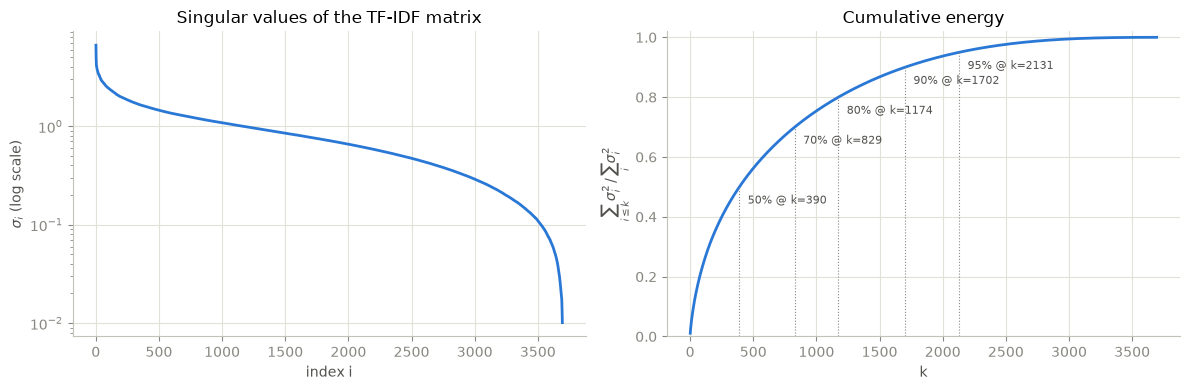

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
idx = np.arange(1, numerical_rank + 1)
axes[0].semilogy(idx, sigma[:numerical_rank], color=COLORS["lsa"])
axes[0].set_xlabel("index i")
axes[0].set_ylabel(r"$\sigma_i$ (log scale)")
axes[0].set_title("Singular values of the TF-IDF matrix")

axes[1].plot(idx, energy[:numerical_rank], color=COLORS["lsa"])
for q, k in k_for_energy.items():
    axes[1].plot([k, k], [0, q], color=COLORS["muted"], linewidth=0.8, linestyle=":")
    axes[1].annotate(f"{q:.0%} @ k={k}", (k, q), textcoords="offset points", xytext=(6, -12), fontsize=8,
                     color="#52514e")
axes[1].set_xlabel("k")
axes[1].set_ylabel(r"$\sum_{i \leq k}\sigma_i^2 \,/\, \sum_i \sigma_i^2$")
axes[1].set_title("Cumulative energy")
axes[1].set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

Phổ suy giảm chậm: không có "khuỷu" rõ rệt, 50 thành phần chỉ giữ khoảng 15% năng lượng và 1000 thành phần khoảng ba phần tư. Đây là đặc điểm điển hình của dữ liệu văn bản thưa, nơi mỗi tài liệu đóng góp vài hướng gần như trực giao, và nó dẫn đến hai hệ quả cho phần sau. Thứ nhất, phương pháp randomized SVD cần power iteration (như đã thấy). Thứ hai, $k$ nhỏ tất yếu bỏ đi một phần lớn của $X$, nên thí nghiệm phân loại sẽ cho thấy bao nhiêu thông tin *phân biệt* nằm trong các thành phần đầu, một câu hỏi khác với việc chúng mang bao nhiêu *năng lượng*.

### **Trực quan hóa tin nhắn trong không gian 2 chiều**

Hai thành phần LSA đầu và hai thành phần chính đầu của ma trận huấn luyện, tô màu theo nhãn. Tin spam được vẽ đè lên trên vì là lớp thiểu số.

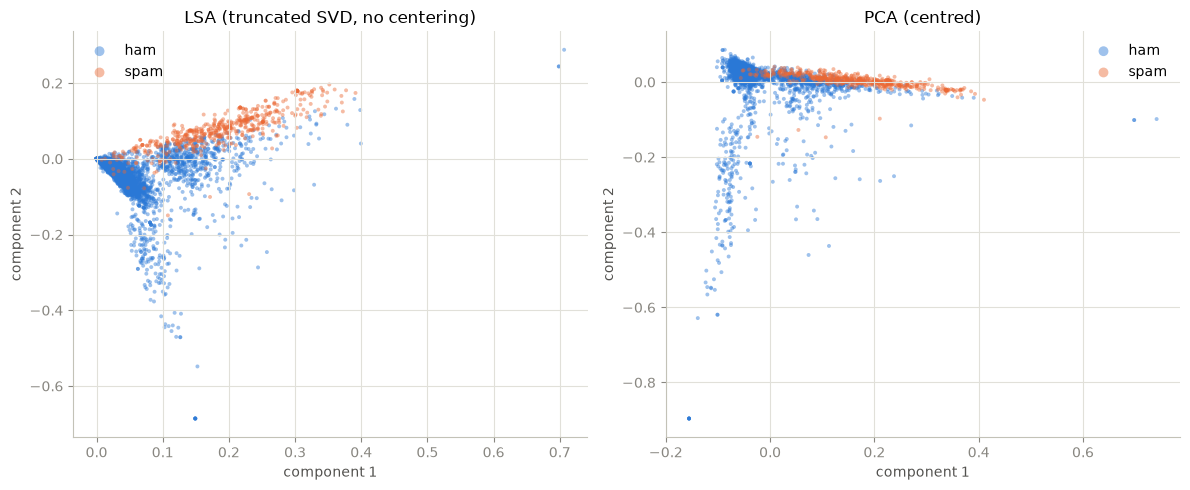

In [17]:
lsa2 = TruncatedSVDScratch(2, algorithm="exact").fit(X_train)
pca2 = PCAScratch(2, algorithm="exact").fit(X_train)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in [(axes[0], lsa2, "LSA (truncated SVD, no centering)"),
                         (axes[1], pca2, "PCA (centred)")]:
    Z = model.transform(X_train)
    for label, name in [(0, "ham"), (1, "spam")]:
        mask = y_train == label
        ax.scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.45, color=COLORS[name], label=name,
                   edgecolors="none")
    ax.set_xlabel("component 1")
    ax.set_ylabel("component 2")
    ax.set_title(title)
    ax.legend(markerscale=2.5)
plt.tight_layout()
plt.show()

Hai thành phần là quá ít để tách lớp, nhưng cấu trúc đã hiện ra: trong cả hai hình, tin spam tập trung ở một vùng. Trong hình LSA, tọa độ thứ nhất không âm với mọi tài liệu (và đúng bằng 0 với vài tin mất hết từ sau tiền xử lý), vì $X$ có phần tử không âm và vectơ kỳ dị đầu của ma trận không âm có thể chọn không âm (Perron–Frobenius); tọa độ đó đo mức độ "trung bình" của một tài liệu hơn là bất cứ điều gì về spam. Tâm hóa loại bỏ trục đó, vì vậy đám mây PCA nằm quanh gốc tọa độ và trải ra cả hai phía.

### **Diễn giải các thành phần**

Mỗi thành phần chính là một hướng $v_j \in \mathbb{R}^d$ trong không gian từ, nên tọa độ của nó có thể đọc như trọng số của từ. Dấu của vectơ kỳ dị là tùy ý; ở đây mỗi thành phần được đổi dấu sao cho điểm chiếu tương quan dương với nhãn spam, nhờ đó các từ có trọng số dương là "phía spam" của trục.

In [18]:
pca6 = PCAScratch(6, algorithm="exact").fit(X_train)
Z6 = pca6.transform(X_train)
for j in range(6):
    corr = np.corrcoef(Z6[:, j], y_train)[0, 1]
    sign = 1.0 if corr >= 0 else -1.0
    v = sign * pca6.components_[j]
    top_pos = np.argsort(v)[::-1][:8]
    top_neg = np.argsort(v)[:8]
    print(f"PC{j + 1}: explained variance ratio {pca6.explained_variance_ratio_[j]:.4f}, "
          f"corr(score, spam) = {sign * corr:+.3f}")
    print("   spam side:", ", ".join(f"{vocab[i]} ({v[i]:+.2f})" for i in top_pos))
    print("   ham side :", ", ".join(f"{vocab[i]} ({v[i]:+.2f})" for i in top_neg))

PC1: explained variance ratio 0.0081, corr(score, spam) = +0.682
   spam side: numtoken (+0.73), numtoken numtoken (+0.32), phonetoken (+0.26), moneytoken (+0.20), free (+0.10), ur (+0.08), txt (+0.07), prize (+0.07)
   ham side : ok (-0.13), come (-0.06), good (-0.06), know (-0.06), like (-0.06), ll (-0.06), home (-0.04), da (-0.04)
PC2: explained variance ratio 0.0061, corr(score, spam) = +0.017
   spam side: know (+0.07), just (+0.05), good (+0.05), want (+0.05), don (+0.04), day (+0.04), love (+0.03), da (+0.03)
   ham side : ok (-0.91), lor (-0.23), ok lor (-0.14), numtoken (-0.12), wat (-0.05), home (-0.04), ya (-0.04), thanx (-0.04)
PC3: explained variance ratio 0.0045, corr(score, spam) = +0.180
   spam side: know (+0.29), like (+0.22), ok (+0.16), phonetoken (+0.10), just (+0.09), did (+0.09), moneytoken (+0.09), dont (+0.08)
   ham side : come (-0.64), home (-0.27), going (-0.21), lor (-0.21), da (-0.14), numtoken (-0.13), got (-0.11), time (-0.10)
PC4: explained variance rat

Thành phần thứ nhất là một trục spam: phía dương gồm các token đại diện (`numtoken`, `phonetoken`, `moneytoken`, tức tin nhắn chứa số, số điện thoại và giá tiền) cùng *free*, *txt* và *prize*, phía âm gồm các từ hội thoại (*ok*, *come*, *good*, *know*), và riêng nó đã có tương quan gần 0,7 với nhãn. Các thành phần còn lại gần như không tương quan với nhãn và mô tả các nguồn biến thiên khác của bộ dữ liệu: những tin xác nhận rất ngắn (*ok*, *lor*, *ok lor*), tin về chuyện về nhà, tin xoay quanh *like* và *know*. PCA không giám sát, nên không gì buộc hướng đầu tiên phải nói về spam; đơn giản spam là nguồn phương sai lớn nhất của bộ dữ liệu này. Tỉ lệ phương sai giải thích nhỏ (dưới 1% mỗi thành phần) vì phổ phẳng, không phải vì các thành phần không quan trọng.

### **Xây dựng mô hình**

Bộ phân loại là như nhau trong mọi thí nghiệm: logistic regression với $C = 1$, `class_weight="balanced"` (để bù cho tỉ lệ 13% spam) và đủ số vòng lặp để hội tụ. Nó được huấn luyện trên

- ma trận TF-IDF đầy đủ (baseline),
- điểm LSA $Z = XV_k$,
- điểm PCA $Z = (X - \mathbf{1}\mu^\mathsf{T})V_k$.

Không chuẩn hóa lại đặc trưng sau phép chiếu. Các cột của $V_k$ trực chuẩn, nên $z = V_k^\mathsf{T}x$ là phép chiếu trực giao: khoảng cách và góc giữa các tài liệu được bảo toàn bên trong không gian con, và tọa độ thứ $i$ có độ lệch chuẩn tỉ lệ với $\sigma_i$. Chuẩn hóa các điểm chiếu sẽ nhân các tọa độ cuối, có phương sai nhỏ, với hệ số lớn, khuếch đại những hướng chủ yếu là nhiễu, và trong các lần chạy thử nó làm giảm F1. Giữ nguyên thang tự nhiên nghĩa là phạt $\ell_2$ của logistic regression tác động lên đúng hình học mà SVD tạo ra.

In [19]:
def make_classifier():
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)


class ReducedClassifier:
    """Reducer (LSA / PCA / none) followed by logistic regression, with timing."""

    def __init__(self, reducer=None):
        self.reducer = reducer
        self.clf = make_classifier()

    def fit(self, X, y):
        t0 = time.perf_counter()
        Z = X if self.reducer is None else self.reducer.fit_transform(X)
        self.clf.fit(Z, y)
        self.fit_time_ = time.perf_counter() - t0
        return self

    def _features(self, X):
        return X if self.reducer is None else self.reducer.transform(X)

    def predict(self, X):
        return self.clf.predict(self._features(X))

    def predict_proba(self, X):
        return self.clf.predict_proba(self._features(X))[:, 1]


def make_model(kind, k=None):
    if kind == "baseline":
        return ReducedClassifier(None)
    if kind == "lsa":
        return ReducedClassifier(TruncatedSVDScratch(k, random_state=RANDOM_STATE))
    if kind == "pca":
        return ReducedClassifier(PCAScratch(k, random_state=RANDOM_STATE))
    raise ValueError(kind)

### **Huấn luyện**

Mỗi mô hình giảm chiều được huấn luyện trên tập huấn luyện con với $k \in \{2, 5, 10, 20, 50, 100, 200, 300, 500, 1000\}$ và chấm điểm trên tập kiểm định. Baseline được huấn luyện một lần trên cùng ma trận TF-IDF của tập huấn luyện con. Thời gian fit bao gồm cả SVD.

In [20]:
K_GRID = [2, 5, 10, 20, 50, 100, 200, 300, 500, 1000]

baseline_val = make_model("baseline").fit(X_sub, y_sub)
baseline_val_f1 = f1_score(y_val, baseline_val.predict(X_val))
print(f"baseline (full TF-IDF, {X_sub.shape[1]} features): validation F1 = {baseline_val_f1:.4f}, "
      f"fit time {baseline_val.fit_time_:.2f} s")

sweep_records = []
for kind in ["lsa", "pca"]:
    for k in K_GRID:
        model = make_model(kind, k).fit(X_sub, y_sub)
        t0 = time.perf_counter()
        pred = model.predict(X_val)
        predict_time = time.perf_counter() - t0
        sweep_records.append({
            "model": kind.upper(), "k": k,
            "val F1": f1_score(y_val, pred), "val accuracy": accuracy_score(y_val, pred),
            "val recall": recall_score(y_val, pred), "val precision": precision_score(y_val, pred),
            "fit time (s)": model.fit_time_, "predict time (s)": predict_time,
        })
        print(f"{kind.upper():4s} k={k:5d}  F1={sweep_records[-1]['val F1']:.4f}  "
              f"fit {model.fit_time_:6.1f} s")
sweep = pd.DataFrame(sweep_records)
sweep.pivot(index="k", columns="model", values=["val F1", "fit time (s)"]).round(4)

baseline (full TF-IDF, 4216 features): validation F1 = 0.9732, fit time 0.02 s
LSA  k=    2  F1=0.7021  fit    0.0 s
LSA  k=    5  F1=0.7869  fit    0.0 s
LSA  k=   10  F1=0.8601  fit    0.1 s


LSA  k=   20  F1=0.8945  fit    0.2 s


LSA  k=   50  F1=0.9167  fit    0.7 s


LSA  k=  100  F1=0.9283  fit    2.3 s


LSA  k=  200  F1=0.9582  fit   13.1 s


...

PCA  k=  200  F1=0.9582  fit   13.6 s


PCA  k=  300  F1=0.9618  fit   21.0 s


PCA  k=  500  F1=0.9655  fit   31.8 s


PCA  k= 1000  F1=0.9695  fit   58.9 s


val F1         fit time (s)         
model     LSA     PCA          LSA      PCA
k                                          
2      0.7021  0.6799       0.0138   0.0177
5      0.7869  0.8106       0.0305   0.0338
10     0.8601  0.8857       0.0648   0.0789
20     0.8945  0.8881       0.2083   0.2070
50     0.9167  0.9167       0.7294   0.7811
100    0.9283  0.9283       2.2602   2.4711
200    0.9582  0.9582      13.1124  13.5589
300    0.9618  0.9618      15.7346  20.9614
500    0.9618  0.9655      26.0647  31.8399
1000   0.9695  0.9695      53.4653  58.8816

### **Vẽ biểu đồ**

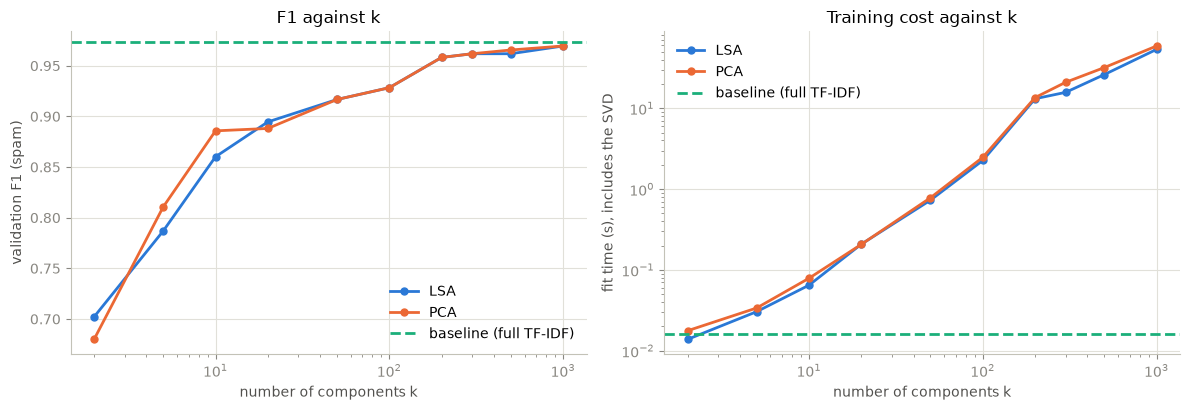

best k for LSA: 1000 (validation F1 = 0.9695)
best k for PCA: 1000 (validation F1 = 0.9695)


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for kind in ["LSA", "PCA"]:
    part = sweep[sweep["model"] == kind]
    axes[0].plot(part["k"], part["val F1"], marker="o", markersize=5, color=COLORS[kind.lower()], label=kind)
    axes[1].plot(part["k"], part["fit time (s)"], marker="o", markersize=5, color=COLORS[kind.lower()], label=kind)
axes[0].axhline(baseline_val_f1, color=COLORS["baseline"], linestyle="--", label="baseline (full TF-IDF)")
axes[0].set_xscale("log")
axes[0].set_xlabel("number of components k")
axes[0].set_ylabel("validation F1 (spam)")
axes[0].set_title("F1 against k")
axes[0].legend(loc="lower right")
axes[1].axhline(baseline_val.fit_time_, color=COLORS["baseline"], linestyle="--", label="baseline (full TF-IDF)")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("number of components k")
axes[1].set_ylabel("fit time (s), includes the SVD")
axes[1].set_title("Training cost against k")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

best = {}
for kind in ["LSA", "PCA"]:
    part = sweep[sweep["model"] == kind].sort_values(["val F1", "k"], ascending=[False, True])
    best[kind] = int(part.iloc[0]["k"])
    print(f"best k for {kind}: {best[kind]} (validation F1 = {part.iloc[0]['val F1']:.4f})")

F1 tăng nhanh đến khoảng $k = 200$ (từ 0,70 ở $k = 2$ lên gần 0,96) rồi tăng chậm, và hai phương pháp giảm chiều gần như không phân biệt được: khi $k$ lên đến hàng trăm, bước tâm hóa chỉ thay đổi vài hướng đầu. Không đường nào chạm tới baseline trên tập kiểm định, điều này nhất quán với phổ phẳng đã thấy: các từ có tính phân biệt nhưng tần suất tài liệu thấp đóng góp ít năng lượng và nằm trong số bị trung bình hóa đi đầu tiên. Chi phí của phép chiếu tăng nhanh hơn tuyến tính theo $k$ vì randomized SVD làm việc với $2k$ cột và mười vòng power iteration, nên các $k$ lớn nhất tốn thời gian fit hơn cả baseline; đổi lại bộ phân loại làm việc trên vài trăm đặc trưng đặc thay vì hàng nghìn đặc trưng thưa.

$k$ có F1 kiểm định cao nhất được giữ lại cho mỗi phương pháp (nếu hòa thì chọn $k$ nhỏ hơn).

### **Kiểm chứng lý thuyết bằng thực nghiệm**

**1. Eckart–Young.** Với mọi $V_k \in \mathbb{R}^{d \times k}$ có cột trực chuẩn, phép chiếu $XV_kV_k^\mathsf{T}$ là ma trận hạng $k$, và định lý (PHẦN 3) khẳng định lựa chọn $V_k$ = $k$ vectơ kỳ dị phải đầu là tối ưu, với

$$
\min_{\operatorname{rank} B \le k} \lVert X - B\rVert_F^2 = \lVert X - XV_kV_k^\mathsf{T}\rVert_F^2 = \sum_{i > k} \sigma_i^2 .
$$

$V_k$ chính xác lấy từ các vectơ riêng Gram của mục trước. Phần dư được đo trực tiếp, theo từng khối hàng để ma trận dư dạng đặc không bao giờ vượt quá vài trăm hàng, và so sánh với (a) giá trị lý thuyết $\sum_{i>k}\sigma_i^2$, (b) một không gian con ngẫu nhiên $k$ chiều và (c) không gian con sinh bởi $k$ hướng tọa độ (từ) có chuẩn cột lớn nhất, tức là cách tốt nhất khi chỉ *chọn* đặc trưng.

In [22]:
def projection_residual(X, V, block=512):
    """||X - X V V^T||_F^2 computed block-wise for an orthonormal V (d x k)."""
    total = 0.0
    for start in range(0, X.shape[0], block):
        Xb = X[start:start + block].toarray()
        total += np.sum((Xb - (Xb @ V) @ V.T) ** 2)
    return total


K_EY = [10, 50, 100, 200, 500, 1000]
col_norm_sq = np.asarray(X_train.multiply(X_train).sum(axis=0)).ravel()
rng = np.random.default_rng(RANDOM_STATE)
ey_records = []
for k in K_EY:
    V_k = V_top[:, :k]
    Q_random, _ = np.linalg.qr(rng.standard_normal((n_terms, k)))
    top_cols = np.argsort(col_norm_sq)[::-1][:k]
    V_cols = np.zeros((n_terms, k))
    V_cols[top_cols, np.arange(k)] = 1.0
    ey_records.append({
        "k": k,
        "SVD subspace (measured)": projection_residual(X_train, V_k),
        "theory sum_{i>k} sigma_i^2": float(np.sum(sigma[k:] ** 2)),
        "random subspace": projection_residual(X_train, Q_random),
        "top-k columns by norm": projection_residual(X_train, V_cols),
    })
eckart_young = pd.DataFrame(ey_records).set_index("k")
eckart_young["|SVD - theory|"] = np.abs(eckart_young["SVD subspace (measured)"]
                                        - eckart_young["theory sum_{i>k} sigma_i^2"]).map("{:.2e}".format)
eckart_young.round(3)

,SVD subspace (measured),theory sum_{i>k} sigma_i^2,random subspace,top-k columns by norm,|SVD - theory|
k,,,,,
10,3883.134,3883.134,4082.911,3924.097,4.55e-13
50,3463.008,3463.008,4053.805,3559.638,4.55e-13
100,3117.619,3117.619,4017.424,3264.360,4.55e-13
200,2638.596,2638.596,3945.522,2870.858,0.00e+00
500,1789.943,1789.943,3728.165,2197.874,2.27e-13
1000,1005.973,1005.973,3366.373,1575.927,1.14e-13


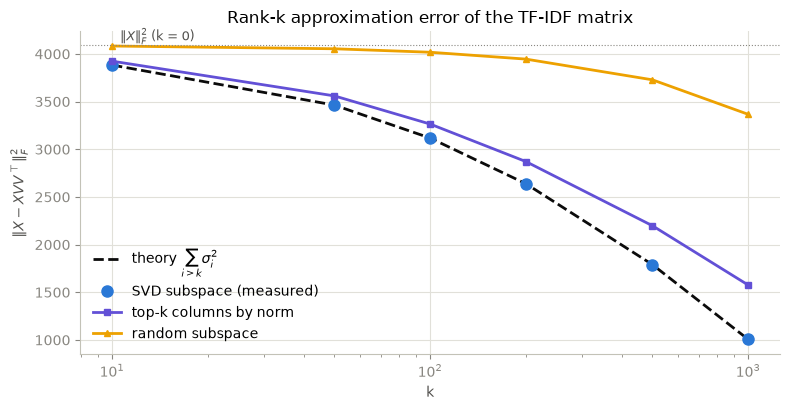

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(K_EY, eckart_young["theory sum_{i>k} sigma_i^2"], color=COLORS["theory"], linestyle="--",
        label=r"theory $\sum_{i>k}\sigma_i^2$")
ax.plot(K_EY, eckart_young["SVD subspace (measured)"], marker="o", linestyle="none", markersize=8,
        color=COLORS["lsa"], label="SVD subspace (measured)")
ax.plot(K_EY, eckart_young["top-k columns by norm"], marker="s", markersize=5, color=COLORS["columns"],
        label="top-k columns by norm")
ax.plot(K_EY, eckart_young["random subspace"], marker="^", markersize=5, color=COLORS["random"],
        label="random subspace")
ax.axhline(fro_sq, color=COLORS["muted"], linewidth=0.8, linestyle=":")
ax.text(K_EY[0], fro_sq, r"  $\Vert X\Vert_F^2$ (k = 0)", va="bottom", color="#52514e", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("k")
ax.set_ylabel(r"$\Vert X - XVV^\top\Vert_F^2$")
ax.set_title("Rank-k approximation error of the TF-IDF matrix")
ax.legend()
plt.tight_layout()
plt.show()

Phần dư đo được của không gian con SVD trùng với $\sum_{i>k}\sigma_i^2$ đến độ chính xác dấu phẩy động, và nhỏ hơn phần dư của mọi không gian con cùng số chiều khác. Không gian con ngẫu nhiên gần như vô dụng (phần dư của nó ở gần $\lVert X\rVert_F^2 \cdot (1 - k/d)$), và chọn $k$ từ phổ biến nhất kém hơn SVD rất nhiều tại mọi $k$: một hướng kỳ dị trộn nhiều từ đồng xuất hiện và nắm bắt được nhiều hơn bất kỳ từ đơn lẻ nào.

**2. PCA là SVD của dữ liệu đã tâm hóa.** Với $X_c = X - \mathbf{1}\mu^\mathsf{T}$ và $C = X_c^\mathsf{T}X_c/(n-1)$ là ma trận hiệp phương sai (covariance matrix) (PHẦN 2):

- trị riêng của $C$ là $\sigma_i^2/(n-1)$ với $\sigma_i$ là giá trị kỳ dị của $X_c$,
- điểm PCA $Z = X_cV_k$ có hiệp phương sai $\Sigma_k^2/(n-1)$, một ma trận chéo: các thành phần không tương quan.

Trị riêng của $C$ được tính qua ma trận Gram đã tâm hóa $X_cX_c^\mathsf{T} = XX^\mathsf{T} - (X\mu)\mathbf{1}^\mathsf{T} - \mathbf{1}(X\mu)^\mathsf{T} + \lVert\mu\rVert^2\mathbf{1}\mathbf{1}^\mathsf{T}$ (có cùng phổ khác 0 với $X_c^\mathsf{T}X_c$), rồi so với phương sai giải thích do `PCAScratch` báo và với phương sai mẫu của các điểm chiếu.

In [24]:
mu = np.asarray(X_train.mean(axis=0)).ravel()
G_centered = CenteredOperator(X_train, mu).gram()
eig_centered = np.sort(np.linalg.eigh(G_centered)[0])[::-1]
cov_eigenvalues = eig_centered / (n_docs - 1)

pca10 = PCAScratch(10, algorithm="exact").fit(X_train)
Z10 = pca10.transform(X_train)
pca_table = pd.DataFrame({
    "eigenvalue of C (centred Gram)": cov_eigenvalues[:10],
    "sigma_i^2 / (n-1) from PCAScratch": pca10.explained_variance_,
    "var(Z_i), ddof=1": Z10.var(axis=0, ddof=1),
}, index=[f"PC{i + 1}" for i in range(10)])
pca_table["max abs difference"] = pca_table.max(axis=1) - pca_table.min(axis=1)
print(pca_table.to_string(float_format=lambda v: f"{v:.8f}"))

cov_Z = np.cov(Z10, rowvar=False)
off_diag = cov_Z - np.diag(np.diag(cov_Z))
print(f"\nlargest |off-diagonal| of Cov(Z): {np.abs(off_diag).max():.2e}  "
      f"(smallest diagonal entry: {np.diag(cov_Z).min():.4e})")
print(f"trace(C) = {cov_eigenvalues.sum():.6f}, total_variance_ from PCAScratch = {pca10.total_variance_:.6f}")

uncentred = sigma[:11] ** 2 / (n_docs - 1)
print("\nsigma_i^2 / (n-1) of the uncentred matrix (first 10):")
print(np.round(uncentred[:10], 6))
interlaced = np.all(uncentred[:10] >= cov_eigenvalues[:10]) and np.all(cov_eigenvalues[:10] >= uncentred[1:11])
print("interlacing lambda_i(uncentred) >= lambda_i(centred) >= lambda_{i+1}(uncentred) holds for i <= 10:", interlaced)

      eigenvalue of C (centred Gram)  sigma_i^2 / (n-1) from PCAScratch  var(Z_i), ddof=1  max abs difference
PC1                       0.00795799                         0.00795799        0.00795799          0.00000000
PC2                       0.00596259                         0.00596259        0.00596259          0.00000000
PC3                       0.00442183                         0.00442183        0.00442183          0.00000000
PC4                       0.00407968                         0.00407968        0.00407968          0.00000000
PC5                       0.00404903                         0.00404903        0.00404903          0.00000000
PC6                       0.00394770                         0.00394770        0.00394770          0.00000000
PC7                       0.00379858                         0.00379858        0.00379858          0.00000000
PC8                       0.00362982                         0.00362982        0.00362982          0.00000000
PC9       

Ba cột trùng nhau đến cỡ $10^{-12}$, và hiệp phương sai của các điểm chiếu là ma trận chéo đến độ chính xác máy. Vì $X^\mathsf{T}X = X_c^\mathsf{T}X_c + n\mu\mu^\mathsf{T}$ là một cập nhật hạng một (PHẦN 2, công thức 20), định lý Cauchy interlacing dự đoán $\lambda_i(X^\mathsf{T}X) \ge \lambda_i(X_c^\mathsf{T}X_c) \ge \lambda_{i+1}(X^\mathsf{T}X)$, và phép kiểm tra in ra xác nhận điều đó: tâm hóa hạ trị riêng đầu nhiều nhất (hướng "tài liệu trung bình" mang một phần đáng kể của $\sigma_1^2$) và dịch phần còn lại của phổ nhiều nhất một vị trí.

Heatmap thể hiện tương quan giữa mười từ xuất hiện nhiều nhất trong từ điển huấn luyện và mười điểm thành phần chính. Hàng là từ, cột là thành phần; thang màu phân kỳ lấy tâm tại 0.

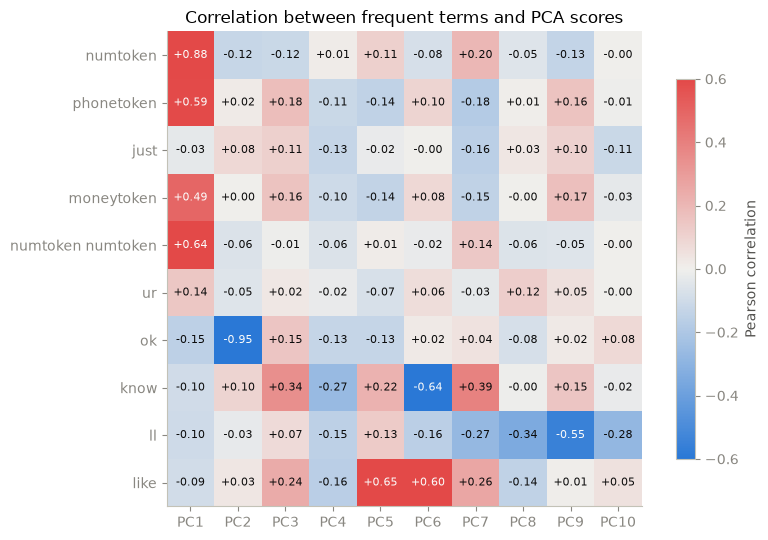

In [25]:
doc_freq = np.asarray((X_train > 0).sum(axis=0)).ravel()
top_terms = np.argsort(doc_freq)[::-1][:10]
term_values = X_train[:, top_terms].toarray()
corr_matrix = np.array([[np.corrcoef(term_values[:, i], Z10[:, j])[0, 1] for j in range(10)]
                        for i in range(len(top_terms))])

fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(corr_matrix, cmap=DIVERGING_CMAP, vmin=-0.6, vmax=0.6)
ax.set_xticks(range(10), [f"PC{j + 1}" for j in range(10)])
ax.set_yticks(range(len(top_terms)), vocab[top_terms])
for i in range(corr_matrix.shape[0]):
    for j in range(corr_matrix.shape[1]):
        ax.text(j, i, f"{corr_matrix[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="#0b0b0b" if abs(corr_matrix[i, j]) < 0.4 else "#fcfcfb")
ax.grid(False)
ax.set_title("Correlation between frequent terms and PCA scores")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
plt.tight_layout()
plt.show()

Mỗi từ phổ biến gắn chặt với một hoặc hai thành phần và gần như không tương quan với các thành phần còn lại, đó là cách PCA phân phối lại các đếm từ có tương quan thành các hướng trực giao. Các từ hay xuất hiện cùng nhau trong cùng loại tin (ví dụ các token `numtoken` và `phonetoken`, hay *call* và *free*) tải lên cùng một thành phần.

**3. Vì sao tâm hóa quan trọng.** Không tâm hóa, vectơ kỳ dị phải đầu của một ma trận không âm hướng gần về phía tài liệu trung bình: thành phần LSA thứ nhất chủ yếu đo mức độ "điển hình" của một tin. Sau khi tâm hóa, hướng đó bị loại bỏ. Các cosin dưới đây định lượng điều này, cùng với tỉ lệ tài liệu có điểm thứ nhất cùng dấu (một thành phần đầu đồng dấu không mang sự tương phản nào giữa các tài liệu).

In [26]:
v1_lsa = V_top[:, 0]
v1_pca = pca10.components_[0]
u1_lsa = U_full[:, 0]
z1_pca = Z10[:, 0]
mu_unit = mu / np.linalg.norm(mu)
print(f"|cos(v1 of SVD, mu)|  = {abs(v1_lsa @ mu_unit):.4f}")
print(f"|cos(v1 of PCA, mu)|  = {abs(v1_pca @ mu_unit):.4f}")
print(f"|cos(v1 of SVD, v1 of PCA)| = {abs(v1_lsa @ v1_pca):.4f}")
same_sign = lambda s: max(np.mean(s >= 0), np.mean(s <= 0))
print(f"share of documents with the same sign on component 1: "
      f"SVD {same_sign(u1_lsa):.3f}, PCA {same_sign(z1_pca):.3f}")
print(f"first singular value: uncentred {sigma[0]:.4f}, centred {np.sqrt(eig_centered[0]):.4f}")

|cos(v1 of SVD, mu)|  = 0.8673
|cos(v1 of PCA, mu)|  = 0.3395
|cos(v1 of SVD, v1 of PCA)| = 0.7441
share of documents with the same sign on component 1: SVD 1.000, PCA 0.732
first singular value: uncentred 6.6591, centred 5.7364


Hướng đầu tiên không tâm hóa gần như song song với vectơ trung bình ($|\cos| \approx 0{,}87$) và cho mọi tài liệu một điểm cùng dấu, trong khi thành phần chính thứ nhất cách xa trung bình hơn nhiều và chia các tài liệu thành hai phía. Trong thực hành đây là lý do PCA, chứ không phải SVD thuần, là công cụ đúng khi mục tiêu là mô tả *sự biến thiên*; với LSA, thành phần đầu không tâm hóa vẫn hữu ích vì với ma trận không âm, hướng trung bình mã hóa từ vựng chung, nhưng không nên nhầm nó với một trục chính.

### **Đánh giá cuối cùng trên tập kiểm tra**

Ba mô hình được fit lại trên toàn bộ tập huấn luyện (bộ vector hóa fit trên tin nhắn huấn luyện) với $k$ đã chọn trên tập kiểm định, và được đánh giá đúng một lần trên tập kiểm tra.

In [27]:
final_models = {
    "Baseline (TF-IDF)": make_model("baseline"),
    f"LSA (k={best['LSA']})": make_model("lsa", best["LSA"]),
    f"PCA (k={best['PCA']})": make_model("pca", best["PCA"]),
}
test_results = {}
test_pred = {}
test_prob = {}
for name, model in final_models.items():
    model.fit(X_train, y_train)
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    predict_time = time.perf_counter() - t0
    prob = model.predict_proba(X_test)
    test_pred[name], test_prob[name] = pred, prob
    test_results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "fit time (s)": model.fit_time_,
        "predict time (s)": predict_time,
        "features": X_train.shape[1] if model.reducer is None else model.reducer.n_components,
    }
results_table = pd.DataFrame(test_results).T
results_table["features"] = results_table["features"].astype(int)
results_table.round({"accuracy": 4, "precision": 4, "recall": 4, "F1": 4, "ROC-AUC": 4,
                     "fit time (s)": 2, "predict time (s)": 4})

,accuracy,precision,recall,F1,ROC-AUC,fit time (s),predict time (s),features
Baseline (TF-IDF),0.9845,0.9389,0.9389,0.9389,0.9964,0.02,0.0005,5649
LSA (k=1000),0.9845,0.9389,0.9389,0.9389,0.9963,88.87,0.0245,1000
PCA (k=1000),0.9845,0.9389,0.9389,0.9389,0.9963,62.04,0.0302,1000


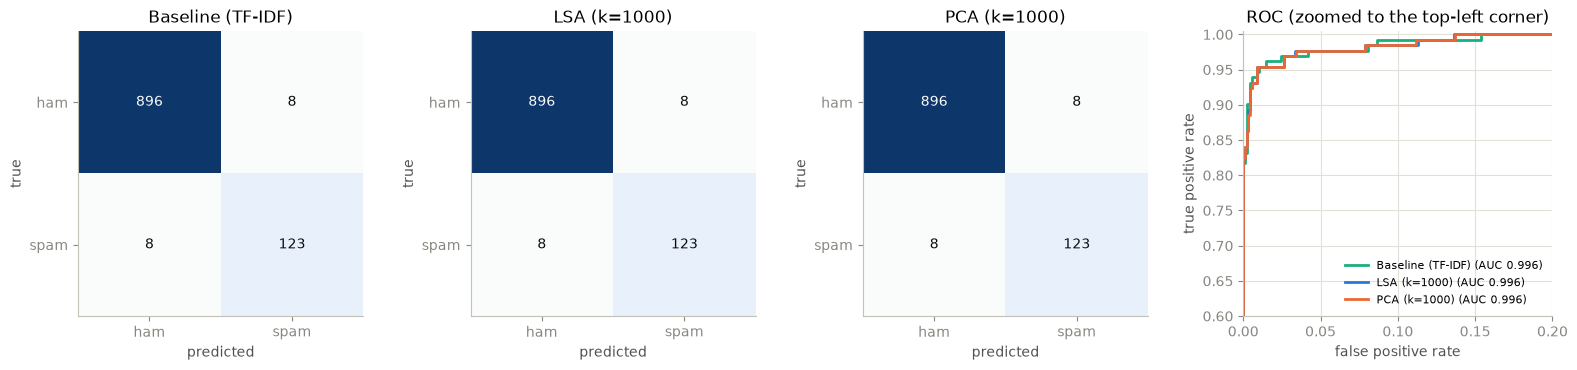

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, pred) in zip(axes[:3], test_pred.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=cm.max())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="#fcfcfb" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
    ax.set_xticks([0, 1], ["ham", "spam"])
    ax.set_yticks([0, 1], ["ham", "spam"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(name)
    ax.grid(False)

ax = axes[3]
for (name, prob), color in zip(test_prob.items(), [COLORS["baseline"], COLORS["lsa"], COLORS["pca"]]):
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], color=COLORS["muted"], linewidth=0.8, linestyle=":")
ax.set_xlim(0, 0.2)
ax.set_ylim(0.6, 1.005)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC (zoomed to the top-left corner)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

In [29]:
for name, pred in test_pred.items():
    print(name)
    print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=4))

Baseline (TF-IDF)
              precision    recall  f1-score   support

         ham     0.9912    0.9912    0.9912       904
        spam     0.9389    0.9389    0.9389       131

    accuracy                         0.9845      1035
   macro avg     0.9650    0.9650    0.9650      1035
weighted avg     0.9845    0.9845    0.9845      1035

LSA (k=1000)
              precision    recall  f1-score   support

         ham     0.9912    0.9912    0.9912       904
        spam     0.9389    0.9389    0.9389       131

    accuracy                         0.9845      1035
   macro avg     0.9650    0.9650    0.9650      1035
weighted avg     0.9845    0.9845    0.9845      1035

PCA (k=1000)
              precision    recall  f1-score   support

         ham     0.9912    0.9912    0.9912       904
        spam     0.9389    0.9389    0.9389       131

    accuracy                         0.9845      1035
   macro avg     0.9650    0.9650    0.9650      1035
weighted avg     0.9845    0.9

In [30]:
def show_errors(name, n=4):
    pred, prob = test_pred[name], test_prob[name]
    wrong = np.flatnonzero(pred != y_test)
    print(f"{name}: {len(wrong)} misclassified test messages")
    for idx in wrong[:n]:
        row = test_df.iloc[idx]
        print(f"  true={row['label']:4s} pred={'spam' if pred[idx] else 'ham':4s} "
              f"p(spam)={prob[idx]:.3f} | {row['text'][:110]}")
    print()


for name in final_models:
    show_errors(name)

Baseline (TF-IDF): 16 misclassified test messages
  true=ham  pred=spam p(spam)=0.598 | "HEY DAS COOL... IKNOW ALL 2 WELLDA PERIL OF STUDENTFINANCIAL CRISIS!SPK 2 U L8R."
  true=ham  pred=spam p(spam)=0.750 | Are you free now?can i call now?
  true=spam pred=ham  p(spam)=0.275 | Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
  true=spam pred=ham  p(spam)=0.462 | You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 75

LSA (k=1000): 16 misclassified test messages
  true=ham  pred=spam p(spam)=0.622 | "HEY DAS COOL... IKNOW ALL 2 WELLDA PERIL OF STUDENTFINANCIAL CRISIS!SPK 2 U L8R."
  true=ham  pred=spam p(spam)=0.762 | Are you free now?can i call now?
  true=spam pred=ham  p(spam)=0.319 | Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
  true=spam pred=ham  p(spam)=0.490 | You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 75

PCA (

Lỗi của các mô hình giảm chiều chủ yếu là tin ham viết theo phong cách spam (ngắn, mệnh lệnh, có số điện thoại hay giá tiền) và tin spam dùng từ vựng hiếm. Phép chiếu không giúp được trường hợp sau: những từ hiếm trong tập huấn luyện hầu như không có trọng số trong các vectơ kỳ dị đầu.

### **Thử mô hình với tin nhắn mới**

`predict_messages` chạy toàn bộ quy trình (chuẩn hóa, TF-IDF với từ điển huấn luyện, chiếu, logistic regression) trên văn bản tự do và báo xác suất spam của từng mô hình.

In [31]:
def predict_messages(messages):
    cleaned = [normalize_text(m) for m in messages]
    X_new = vectorizer.transform(cleaned)
    table = pd.DataFrame({"message": messages})
    for name, model in final_models.items():
        table[f"p(spam) {name}"] = model.predict_proba(X_new).round(3)
    pca_name = [name for name in final_models if name.startswith("PCA")][0]
    table["verdict (PCA)"] = np.where(table[f"p(spam) {pca_name}"] >= 0.5, "spam", "ham")
    return table


new_messages = [
    "Hey, are we still meeting at the library at 5? I'll bring the notes from today's lecture.",
    "URGENT! You have won a £1000 cash prize. Call 09061234567 now to claim. T&Cs apply.",
    "Free entry to our weekly competition, text WIN to 85233 to receive your prize now!",
    "Mum says dinner is at 7, can you pick up some bread on your way home?",
    "Your mobile number has been selected for a free holiday. Reply YES or call 0800 123 4567.",
]
pd.set_option("display.max_colwidth", 70)
predict_messages(new_messages)

,message,p(spam) Baseline (TF-IDF),p(spam) LSA (k=1000),p(spam) PCA (k=1000),verdict (PCA)
0,"Hey, are we still meeting at the library at 5? I'll bring the note...",0.088,0.090,0.089,ham
1,URGENT! You have won a £1000 cash prize. Call 09061234567 now to c...,0.983,0.984,0.984,spam
2,"Free entry to our weekly competition, text WIN to 85233 to receive...",0.939,0.952,0.951,spam
3,"Mum says dinner is at 7, can you pick up some bread on your way home?",0.070,0.065,0.066,ham
4,Your mobile number has been selected for a free holiday. Reply YES...,0.961,0.965,0.966,spam


### **Kết luận**

**Về lý thuyết.** Mọi kết quả trong `slide/script.md` đều được tái hiện bằng số trên ma trận TF-IDF $4136 \times 5649$:

- Thuật toán SVD xây dựng từ chứng minh tồn tại (`svd_via_eig`) trùng với `numpy.linalg.svd` đến cỡ $10^{-15}$, kể cả trên khối TF-IDF có hàng phụ thuộc tuyến tính, nhờ ngưỡng hạng đặt trên $\lambda_i$ thay vì $\sigma_i$.
- Randomized SVD với $p = k$, $q = 10$ sai lệch dưới $3 \cdot 10^{-4}$ so với ARPACK ở $k = 50$, trong khi mặc định $p = 10$, $q = 4$ lệch gần 5% vì phổ của dữ liệu văn bản suy giảm rất chậm (50 thành phần chỉ giữ khoảng 15% năng lượng, 1000 thành phần khoảng 75%).
- Định lý Eckart–Young: phần dư đo trực tiếp $\lVert X - XV_kV_k^\mathsf{T}\rVert_F^2$ trùng với $\sum_{i>k}\sigma_i^2$ đến sai số làm tròn tại mọi $k$ thử nghiệm, và thấp hơn hẳn không gian con ngẫu nhiên cũng như phép chọn $k$ từ phổ biến nhất (ở $k = 1000$: 1006 so với 3366 và 1576).
- PCA là SVD của dữ liệu đã tâm hóa: trị riêng của ma trận hiệp phương sai, $\sigma_i^2/(n-1)$ và phương sai của các điểm chiếu trùng nhau đến $10^{-12}$; $\operatorname{Cov}(Z)$ chéo với phần tử ngoài đường chéo cỡ $10^{-18}$; các trị riêng tâm hóa và không tâm hóa đan xen nhau đúng như định lý Cauchy dự đoán.
- Vai trò của tâm hóa: $|\cos(v_1^{\text{SVD}}, \mu)| = 0{,}87$ và gần 100% tài liệu cùng dấu trên thành phần đầu, so với $|\cos(v_1^{\text{PCA}}, \mu)| = 0{,}34$ và chỉ 73% cùng dấu.

**Về phân loại.** Trên tập kiểm định, F1 của cả LSA và PCA tăng từ 0,70 ($k = 2$) lên 0,93 ($k = 100$), 0,96 ($k = 200$–$300$) và 0,97 ($k = 1000$), so với 0,973 của baseline dùng toàn bộ TF-IDF; $k = 1000$ được chọn cho cả hai. Trên tập kiểm tra, ba mô hình cho kết quả giống hệt nhau: accuracy 0,9845, precision = recall = F1 (spam) = 0,9389, ROC-AUC 0,996, cùng 16 tin bị phân loại sai. Như vậy với bộ dữ liệu này, giảm chiều **không cải thiện** độ chính xác; nó chỉ bắt kịp baseline khi $k$ đủ lớn để không gian con chứa gần hết thông tin mà logistic regression cần. Với $k$ nhỏ hơn, các từ hiếm nhưng mang tính phân biệt nằm ở phần đuôi của phổ và bị cắt bỏ, đúng như Định lý Eckart–Young mô tả: phép chiếu tối ưu theo năng lượng chứ không theo khả năng phân loại. LSA và PCA cho kết quả gần như trùng nhau ở mọi $k \ge 50$ vì hai ma trận Gram chỉ khác nhau một số hạng hạng một.

Lợi ích thực sự của bước giảm chiều ở đây nằm ở chỗ khác: biểu diễn đặc 1000 chiều thay cho 5649 chiều thưa (dùng được cho các mô hình không xử lý dữ liệu thưa), các trục có thể diễn giải bằng từ, và khả năng trực quan hóa. Cái giá phải trả là thời gian tính SVD: khoảng một đến hai phút cho $k = 1000$ so với vài phần trăm giây để huấn luyện baseline.

**Hạn chế.** Mô hình hoàn toàn tuyến tính trên biểu diễn bag-of-words, nên không nắm được thứ tự từ hay ngữ nghĩa ngoài đồng xuất hiện; từ điển và idf cố định theo tập huấn luyện, và khi từ vựng thay đổi (spam mới, ngôn ngữ khác) phải tính lại cả TF-IDF lẫn SVD; bộ dữ liệu nhỏ, một ngôn ngữ, và tập kiểm tra chỉ có 131 tin spam nên chênh lệch dưới 1% giữa các mô hình không có ý nghĩa thống kê. Hướng phát triển tự nhiên là dùng embedding học sẵn thay cho TF-IDF, dùng incremental SVD khi dữ liệu đến theo dòng, hoặc kết hợp PCA với mô hình phi tuyến trên không gian đã giảm chiều.